# Profit per day per store

In [1]:
# Important: When you run this file, make sure you run it from the The-Supply-Chain-Paradox directory


import pandas as pd
import matplotlib.pyplot as plt


prod  = pd.read_csv("../../../Project data/products.csv", usecols=["item_id", "department", "unit_cost"])
sales = pd.read_csv("../../../Project data/sales_train.csv.gz", dtype={"store_id": "int16", "item_id": "int32", "unit_sales": "int32"})
prcs  = pd.read_csv("../../../Project data/prices.csv", dtype={"store_id": "int16", "item_id": "int32", "ad_week": "int32"})
clndr = pd.read_csv("../../../Project data/calendar.csv", usecols=["date", "ad_week"])

# take out trailing spaces from products.csv
prod["department"] = prod["department"].str.strip()

# Some sales have outlandishly high values, so they need to be taken out
SENTINELS = [99999, 12000, 9999, 4800, 999]

bad = sales["unit_sales"].isin(SENTINELS)
print(f"Removing {bad.sum()} sentinel rows")   # expect 18
sales = sales[~bad].copy()



# fix date formatting
def parse_dates(s):
    s = s.str.strip()
    uniq = pd.Series(s.unique())
    iso = pd.to_datetime(uniq, format="%Y-%m-%d", errors="coerce")
    us  = pd.to_datetime(uniq, format="%m/%d/%Y", errors="coerce")
    mapping = dict(zip(uniq, iso.fillna(us)))
    out = s.map(mapping)
    assert out.notna().all(), f"unparsed: {s[out.isna()].unique()[:10]}"
    return out

sales["date"] = parse_dates(sales["date"])
clndr["date"] = parse_dates(clndr["date"])

# store 131 and 214 report their prices in cents, so that needs to be converted
prcs.loc[prcs["store_id"].isin([131, 214]), "sell_price"] /= 100

# merge the data
print("begining merge")

merged = (
    sales
    .merge(clndr, on="date", how="left", validate="m:1")
    .merge(prod, on="item_id", how="left", validate="m:1")
    .merge(prcs, on=["store_id", "item_id", "ad_week"], how="left", validate="m:1")
    [["date", "ad_week", "store_id", "item_id",
      "department", "unit_cost", "unit_sales", "sell_price"]]
)

# take out all rows without a unit price
rows_before = len(merged)
merged = merged.dropna(subset=["unit_cost"]).copy()
print(f"Dropped {rows_before - len(merged)} sales rows with no unit_cost")

print("finished merging")

merged["profit"] = (merged["sell_price"] - merged["unit_cost"]) * merged["unit_sales"]

profit_by_dept_day = merged.groupby(["date", "department"], observed=True)["profit"].sum().reset_index()

Removing 18 sentinel rows
begining merge
Dropped 176880 sales rows with no unit_cost
finished merging


In [2]:
# profit per day, per store, one column per department
store_dept_daily = (
    merged.groupby(["store_id", "date"], observed=True)["profit"]
    .sum()
)

stores = sorted(merged["store_id"].unique())

store_dict = {}

for store in stores:
    df = store_dept_daily.loc[store]

    store_dict[store] = pd.DataFrame(df).reset_index()

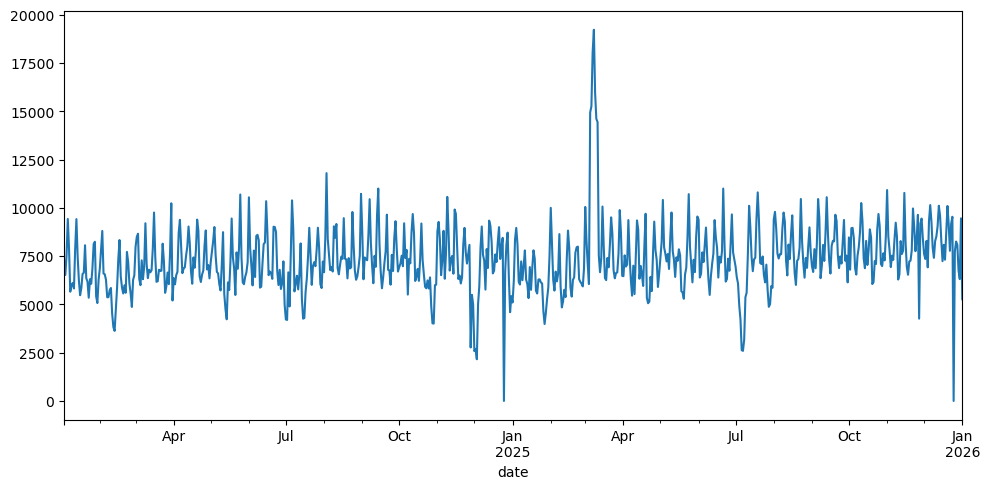

In [3]:
# store_dict[104]
df = store_dict[104]
df.set_index('date')['profit'].plot(figsize=(10, 5))
plt.tight_layout()
plt.show()

# Stock availability

In [4]:
# Obtain necessary datasets
import pandas as pd

Calendar = pd.read_csv('../../../Project data/calendar.csv')
Inventory = pd.read_csv('../../../Project data/inventory.csv.gz')
Products = pd.read_csv('../../../Project data/products.csv')
Stores = pd.read_csv('../../../Project data/stores.csv')

Inventory["date"] = parse_dates(Inventory["date"])
# Products["date"] = parse_dates(Products["date"])

# Create a list with the item ids
item_ids = [i for i in Products['item_id']]

# Create a list with the store ids\
store_ids = [i for i in Stores['store_id']]

# Create a list with the available dates
dates = [i for i in Calendar['date']]

# Create a list with the available departments
Departments = list({i.replace(" ", "") for i in Products['department']})

# Create a dictionary where the keys are the item ids and the values are the corresponding departments
item_department_dict = {row['item_id']: row['department'].replace(" ", "") for index, row in Products.iterrows()}

# Create a list of items for each department
department_items_dict = {department: [item for item in item_ids if item_department_dict[item] == department] for department in Departments}


# Create a new dataset that combines that adds the departments feature to the inventory dataset
Inventory_with_departments = Inventory.copy()
Inventory_with_departments['department'] = Inventory_with_departments['item_id'].map(item_department_dict)
Inventory_with_departments

,date,store_id,item_id,on_hand,received,shrink,department
0,2024-01-03,104,971509,100,100,1,Produce
1,2024-01-03,104,652089,220,220,3,Produce
2,2024-01-03,104,329628,100,100,0,Produce
3,2024-01-03,104,406789,24,24,1,Produce
4,2024-01-03,104,813467,24,24,0,Produce
...,...,...,...,...,...,...,...
8759995,2026-01-01,318,248758,6,0,0,Health&Beauty
8759996,2026-01-01,318,175134,8,0,0,Health&Beauty
8759997,2026-01-01,318,165350,19,0,0,Health&Beauty
8759998,2026-01-01,318,980056,0,0,0,Health&Beauty


In [5]:
features_per_store = {}

for store in store_ids:
    
    Inventory_with_departments_per_store = Inventory_with_departments.loc[
        (Inventory_with_departments["store_id"] == store)
    ]
    
    New_table = (
        Inventory_with_departments_per_store.groupby("date", as_index=False)
          .agg(
              total_on_hand=("on_hand", "sum"),
              num_zero=("on_hand", lambda s: (s == 0).sum()),
              num_items=("on_hand", "size"),
          )
    )
    
    New_table["zero_ratio"] = New_table["num_zero"] / New_table["num_items"]
    
    # Keep only the requested columns
    # New_table = New_table[["date", "total_on_hand", "num_zero", "num_items", "zero_ratio"]]
    New_table = New_table[["date", "zero_ratio"]]

    features_per_store[store] = New_table

In [6]:
# features_per_store[104]

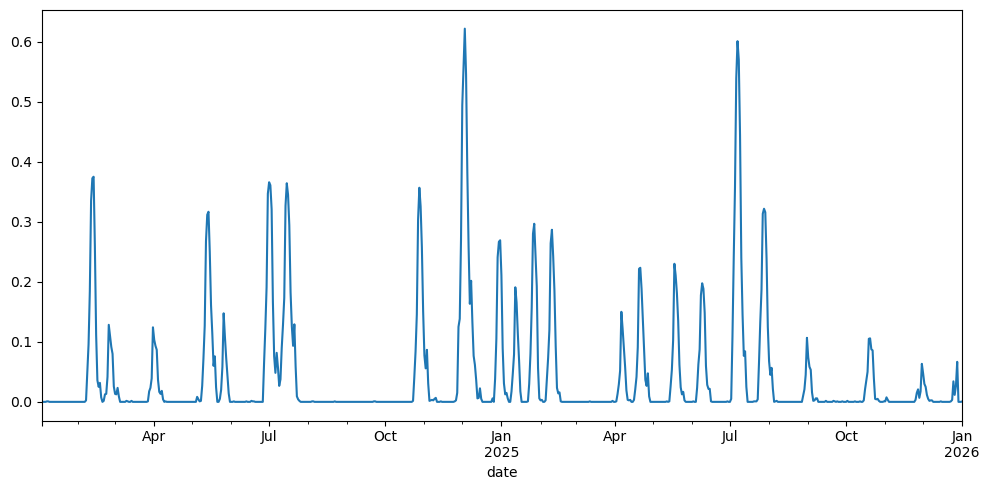

In [7]:
df = features_per_store[104]
df.set_index('date')['zero_ratio'].plot(figsize=(10, 5))
plt.tight_layout()
plt.show()

In [8]:
zero_ratio_profit_dict = {}
for store in store_ids:
    
    df1 = store_dict[store]
    df2 = features_per_store[store]
    zero_ratio_profit_dict[store] = pd.merge(df1, df2, on='date', how='inner')

In [9]:
zero_ratio_profit_dict[104]

,date,profit,zero_ratio
0,2024-01-03,7264.91,0.000000
1,2024-01-04,6522.52,0.000000
2,2024-01-05,7561.08,0.000000
3,2024-01-06,9422.74,0.000000
4,2024-01-07,7892.15,0.000833
...,...,...,...
725,2025-12-28,8090.64,0.066667
726,2025-12-29,6746.16,0.000000
727,2025-12-30,6308.56,0.000000
728,2025-12-31,9456.08,0.000000


# Sale type

In [10]:
Sale_type = pd.read_csv('store_sale_day_table.csv')
Sale_type["date"] = parse_dates(Sale_type["date"])
Sale_type_copy = Sale_type.copy()
Sale_type_copy["sale_week_type"] = Sale_type_copy["sale_week_type"].map({"Low-promotion": 0, "Other ad week": 1, "Candidate big-sale": 2})

In [11]:
Sale_type_per_store = {}
Sale_type_per_store_copy = {}
for store in store_ids:
    Sale_type_per_store[store] = Sale_type.loc[(Sale_type["store_id"] == store)][["date","sale_week_type"]]
    Sale_type_per_store_copy[store] = Sale_type_copy.loc[(Sale_type_copy["store_id"] == store)][["date","sale_week_type"]]
    

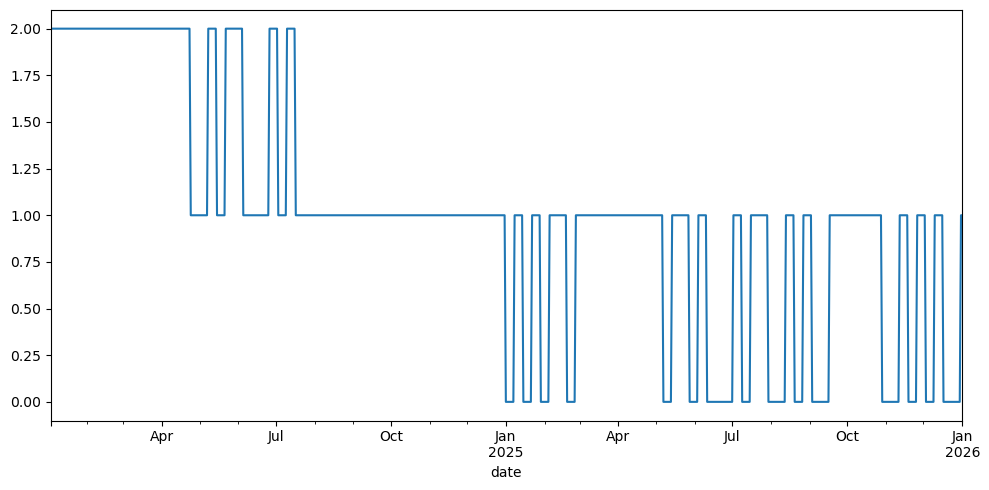

In [12]:
df = Sale_type_per_store_copy[104]
df.set_index('date')['sale_week_type'].plot(figsize=(10, 5))
plt.tight_layout()
plt.show()

In [13]:
zero_ratio_profit_Sale_type_dict = {}
for store in store_ids:
    
    df1 = zero_ratio_profit_dict[store]
    df2 = Sale_type_per_store[store]
    zero_ratio_profit_Sale_type_dict[store] = pd.merge(df1, df2, on='date', how='inner')

In [51]:
zero_ratio_profit_Sale_type_dict[104][["date", "zero_ratio","sale_week_type","profit"]]

,date,zero_ratio,sale_week_type,profit
0,2024-01-03,0.000000,Candidate big-sale,7264.91
1,2024-01-04,0.000000,Candidate big-sale,6522.52
2,2024-01-05,0.000000,Candidate big-sale,7561.08
3,2024-01-06,0.000000,Candidate big-sale,9422.74
4,2024-01-07,0.000833,Candidate big-sale,7892.15
...,...,...,...,...
725,2025-12-28,0.066667,Low-promotion,8090.64
726,2025-12-29,0.000000,Low-promotion,6746.16
727,2025-12-30,0.000000,Low-promotion,6308.56
728,2025-12-31,0.000000,Other ad week,9456.08


In [15]:
df = zero_ratio_profit_Sale_type_dict[104]
df['profit'].mean()

np.float64(7344.3754931506855)

# Naive Bayes classifier

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report,
                             log_loss, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score)

def Naive_Bayes_feature_selection_and_split(dataset_dict, features: list, target,
                                            train_frac=0.7, random_state=42):
    """
    Build features and split each store's data into 70/30 train/test.

    The profit threshold is computed on the full dataset (both years)
    before splitting. This is a small, deliberate simplification:
    the mean is a single scalar summary of the target and the leakage
    is negligible relative to the feature engineering itself.
    """
    from sklearn.model_selection import train_test_split

    Naive_Bayes_features = {}

    for store in dataset_dict.keys():
        df = dataset_dict[store].copy()
        df['date'] = pd.to_datetime(df['date'])

        # --- Mean profit over the ENTIRE dataset ---
        mean_profit = df['profit'].mean()
        df['profit_level'] = np.where(df['profit'] > mean_profit, 'high', 'low')

        # --- Weekday ---
        df['weekday'] = df['date'].dt.day_name()

        # --- Discretize zero stock ---
        df['zero_stock_level'] = np.select(
            [df['zero_ratio'].between(0, 0.1, inclusive='left'),
             df['zero_ratio'].between(0.1, 0.3, inclusive='left')],
            ['low', 'moderate'],
            default='high'
        )

        # --- 70/30 split, stratified on target ---
        train_df, test_df = train_test_split(
            df,
            train_size=train_frac,
            random_state=random_state,
            shuffle=True,
            stratify=df[target] if df[target].nunique() > 1 else None,
        )

        train_df = train_df.sort_values('date')
        test_df  = test_df.sort_values('date')

        Naive_Bayes_features[store] = {
            'train': train_df[['date'] + features + [target]],
            'test':  test_df [['date'] + features + [target]],
        }

    return Naive_Bayes_features

def Naive_Bayes_Classifier(FEATURES, TARGET, Naive_Bayes_features, store = 104, verbose=True):
    train_df = Naive_Bayes_features[store]['train'].copy()
    test_df  = Naive_Bayes_features[store]['test'].copy()

    if len(train_df) == 0 or len(test_df) == 0:
        raise ValueError(f"Empty split for store {store}: "
                         f"train={len(train_df)}, test={len(test_df)}")

    CATEGORY_MAP = {
        'weekday':          ['Monday', 'Tuesday', 'Wednesday', 'Thursday',
                             'Friday', 'Saturday', 'Sunday'],
        'zero_stock_level': ['low', 'moderate', 'high'],
        'sale_week_type':   ['Low-promotion', 'Other ad week', 'Candidate big-sale'],
    }
    encoder = OrdinalEncoder(
        categories=[CATEGORY_MAP[f] for f in FEATURES],
        handle_unknown='use_encoded_value',
        unknown_value=-1,
    )

    X_train = encoder.fit_transform(train_df[FEATURES])
    X_test  = encoder.transform(test_df[FEATURES])
    y_train = train_df[TARGET].values
    y_test  = test_df[TARGET].values

    model = CategoricalNB(alpha=1.0)   # Laplace smoothing
    model.fit(X_train, y_train)

    proba_test = model.predict_proba(X_test)
    classes    = list(model.classes_)
    test_df['p_high'] = proba_test[:, classes.index('high')]
    test_df['p_low']  = proba_test[:, classes.index('low')]
    test_df['pred']   = model.predict(X_test)

    acc    = accuracy_score(y_test, test_df['pred'])
    ll     = log_loss(y_test, proba_test, labels=classes)
    report = classification_report(y_test, test_df['pred'],
                                   output_dict=True, zero_division=0)

    # ---- ROC / AUC ----
    # Positive class = 'high'. Build a binary y_true and use p_high as the score.
    y_true_bin = (y_test == 'high').astype(int)
    y_score    = test_df['p_high'].values

    # roc_auc_score needs both classes present in y_true_bin
    if y_true_bin.min() == y_true_bin.max():
        auc = np.nan
        fpr = tpr = thresholds = None
        if verbose:
            print("\n[WARNING] Test set contains only one class in "
                  f"'{TARGET}'; ROC/AUC cannot be computed.")
    else:
        fpr, tpr, thresholds = roc_curve(y_true_bin, y_score)
        auc = roc_auc_score(y_true_bin, y_score)

    if verbose:
        print(f"Store: {store} | Features: {FEATURES}")
        print("Train size:", len(train_df), "| Test size:", len(test_df))
        print("Accuracy:", acc, "| Log loss:", ll)
        print(classification_report(y_test, test_df['pred'], zero_division=0))
        print("AUC:", auc)

    # ---- Confusion matrices ----
    labels  = ['high', 'low']
    cm      = confusion_matrix(y_test, test_df['pred'], labels=labels)
    cm_norm = confusion_matrix(y_test, test_df['pred'], labels=labels, normalize='true')

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, mat, fmt, title in zip(
        axes, [cm, cm_norm], ['d', '.2f'],
        ['Counts', 'Row-normalized (recall per class)']
    ):
        ConfusionMatrixDisplay(mat, display_labels=labels).plot(
            ax=ax, cmap='Blues', colorbar=False, values_format=fmt
        )
        ax.set_title(title)
    plt.tight_layout()
    plt.show()
    plt.close(fig)

    # ---- ROC curve ----
    if fpr is not None:
        fig, ax = plt.subplots(figsize=(5, 5))
        ax.plot(fpr, tpr, label=f'AUC = {auc:.3f}', color='C0')
        ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Chance')
        ax.set_xlabel('False Positive Rate')
        ax.set_ylabel('True Positive Rate')
        ax.set_title(f'ROC — store {store} — positive class: high')
        ax.legend(loc='lower right')
        ax.set_aspect('equal')
        plt.tight_layout()
        plt.show()
        plt.close(fig)

    return {'model': model, 'encoder': encoder, 'test_df': test_df,
            'accuracy': acc, 'log_loss': ll, 'report': report,
            'auc': auc, 'fpr': fpr, 'tpr': tpr}

In [37]:
# def Naive_Bayes_feature_selection_and_split(dataset_dict, features:list, target):
#     Naive_Bayes_features = {}
#     for store in store_ids:
#         df = dataset_dict[store].copy()
#         df['date'] = pd.to_datetime(df['date'])
    
#         # Identify the first year in this store's data
#         first_year = df['date'].dt.year.min()
    
#         # Mean profit computed on the first year only
#         mean_profit = df.loc[df['date'].dt.year == first_year, 'profit'].mean()
    
#         # Apply that threshold to ALL rows (both years)
#         df['profit_level'] = np.where(df['profit'] > mean_profit, 'high', 'low')
    
#         # Add weekday
#         df['weekday'] = df['date'].dt.day_name()
    
#         # Discretize zero stock
#         df['zero_stock_level'] = np.select(
#             [df['zero_ratio'].between(0, 0.1, inclusive='left'),
#              df['zero_ratio'].between(0.1, 0.3, inclusive='left')],
#             ['low', 'moderate'],
#             default='high'
#         )
    
#         train_df = df[df['date'].dt.year == first_year]
#         test_df  = df[df['date'].dt.year ==  first_year + 1]
#         Naive_Bayes_features[store] = {
#             'train': train_df[["date"] + features + [target]],
#             'test':  test_df [["date"] + features + [target]],
#         }
#     return Naive_Bayes_features


# def Naive_Bayes_Classifier(FEATURES, TARGET, Naive_Bayes_features, store):
    
#     train_df = Naive_Bayes_features[store]['train'].copy()
#     test_df  = Naive_Bayes_features[store]['test'].copy()
    
#     # Encode categorical features (declared explicitly so train/test match)

#     CATEGORY_MAP = {
#     'weekday':          ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'],
#     'zero_stock_level': ['low', 'moderate', 'high'],
#     'sale_week_type':   ['Low-promotion', 'Other ad week', 'Candidate big-sale'],
#     }
#     encoder = OrdinalEncoder(categories=[CATEGORY_MAP[f] for f in FEATURES])
    
#     X_train = encoder.fit_transform(train_df[FEATURES])
#     X_test  = encoder.transform(test_df[FEATURES])
#     y_train = train_df[TARGET].values
#     y_test  = test_df[TARGET].values
    
#     # Fit Naive Bayes
#     model = CategoricalNB(alpha=1.0)
#     model.fit(X_train, y_train)
    
#     # Predict probabilities
#     proba_test = model.predict_proba(X_test)
#     classes    = list(model.classes_)
#     test_df['p_high'] = proba_test[:, classes.index('high')]
#     test_df['p_low']  = proba_test[:, classes.index('low')]
#     test_df['pred']   = model.predict(X_test)
    
#     # Evaluate
#     print("Train size:", len(train_df), "| Test size:", len(test_df))
#     print("Train label counts:\n", train_df[TARGET].value_counts())
#     print("Test label counts:\n",  test_df[TARGET].value_counts())
#     print("\nAccuracy:", accuracy_score(y_test, test_df['pred']))
#     print("\nClassification report:\n", classification_report(y_test, test_df['pred'], zero_division=0))
#     print("Log loss:", log_loss(y_test, proba_test, labels=classes))

#     cm = confusion_matrix(y_test, test_df['pred'], labels=labels)
#     cm_norm = confusion_matrix(y_test, test_df['pred'], labels=labels, normalize='true')
    
#     fig, axes = plt.subplots(1, 2, figsize=(10, 4))
#     for ax, mat, fmt, title in zip(
#         axes,
#         [cm, cm_norm],
#         ['d', '.2f'],
#         ['Counts', 'Row-normalized (recall per class)']
#     ):
#         ConfusionMatrixDisplay(mat, display_labels=labels).plot(
#             ax=ax, cmap='Blues', colorbar=False, values_format=fmt
#         )
#         ax.set_title(title)
#     plt.tight_layout()
#     plt.show()

# def Naive_Bayes_Classifier(FEATURES, TARGET, Naive_Bayes_features, store, verbose=True):
#     train_df = Naive_Bayes_features[store]['train'].copy()
#     test_df  = Naive_Bayes_features[store]['test'].copy()

#     if len(train_df) == 0 or len(test_df) == 0:
#         raise ValueError(f"Empty split for store {store}: "
#                          f"train={len(train_df)}, test={len(test_df)}")

#     CATEGORY_MAP = {
#         'weekday':          ['Monday', 'Tuesday', 'Wednesday', 'Thursday',
#                              'Friday', 'Saturday', 'Sunday'],
#         'zero_stock_level': ['low', 'moderate', 'high'],
#         'sale_week_type':   ['Low-promotion', 'Other ad week', 'Candidate big-sale'],
#     }
#     encoder = OrdinalEncoder(
#         categories=[CATEGORY_MAP[f] for f in FEATURES],
#         handle_unknown='use_encoded_value',
#         unknown_value=-1,
#     )

#     X_train = encoder.fit_transform(train_df[FEATURES])
#     X_test  = encoder.transform(test_df[FEATURES])
#     y_train = train_df[TARGET].values
#     y_test  = test_df[TARGET].values

#     model = CategoricalNB(alpha=1.0)   # Laplace smoothing
#     model.fit(X_train, y_train)

#     proba_test = model.predict_proba(X_test)
#     classes    = list(model.classes_)
#     test_df['p_high'] = proba_test[:, classes.index('high')]
#     test_df['p_low']  = proba_test[:, classes.index('low')]
#     test_df['pred']   = model.predict(X_test)

#     acc = accuracy_score(y_test, test_df['pred'])
#     ll  = log_loss(y_test, proba_test, labels=classes)
#     report = classification_report(y_test, test_df['pred'],
#                                    output_dict=True, zero_division=0)

#     if verbose:
#         print(f"Store: {store} | Features: {FEATURES}")
#         print("Train size:", len(train_df), "| Test size:", len(test_df))
#         print("Accuracy:", acc, "| Log loss:", ll)
#         print(classification_report(y_test, test_df['pred'], zero_division=0))

#     labels = ['high', 'low']
#     cm      = confusion_matrix(y_test, test_df['pred'], labels=labels)
#     cm_norm = confusion_matrix(y_test, test_df['pred'], labels=labels, normalize='true')

#     fig, axes = plt.subplots(1, 2, figsize=(10, 4))
#     for ax, mat, fmt, title in zip(
#         axes, [cm, cm_norm], ['d', '.2f'],
#         ['Counts', 'Row-normalized (recall per class)']
#     ):
#         ConfusionMatrixDisplay(mat, display_labels=labels).plot(
#             ax=ax, cmap='Blues', colorbar=False, values_format=fmt
#         )
#         ax.set_title(title)
#     plt.tight_layout()
#     plt.show()
#     plt.close(fig)

#     return {'model': model, 'encoder': encoder, 'test_df': test_df,
#             'accuracy': acc, 'log_loss': ll, 'report': report}

### All features

In [56]:
Naive_Bayes_features[104]['train']

,date,weekday,zero_stock_level,sale_week_type,profit_level
1,2024-01-04,Thursday,low,Candidate big-sale,low
2,2024-01-05,Friday,low,Candidate big-sale,high
4,2024-01-07,Sunday,low,Candidate big-sale,high
5,2024-01-08,Monday,low,Candidate big-sale,low
8,2024-01-11,Thursday,low,Candidate big-sale,low
...,...,...,...,...,...
718,2025-12-21,Sunday,low,Low-promotion,high
719,2025-12-22,Monday,low,Low-promotion,high
721,2025-12-24,Wednesday,low,Low-promotion,high
722,2025-12-25,Thursday,low,Low-promotion,low


In [57]:
# store = 104

Store: 104 | Features: ['weekday', 'zero_stock_level', 'sale_week_type']
Train size: 510 | Test size: 220
Accuracy: 0.8272727272727273 | Log loss: 0.4000338456744871
              precision    recall  f1-score   support

        high       0.83      0.78      0.81       102
         low       0.82      0.86      0.84       118

    accuracy                           0.83       220
   macro avg       0.83      0.82      0.83       220
weighted avg       0.83      0.83      0.83       220

AUC: 0.8940262545696245


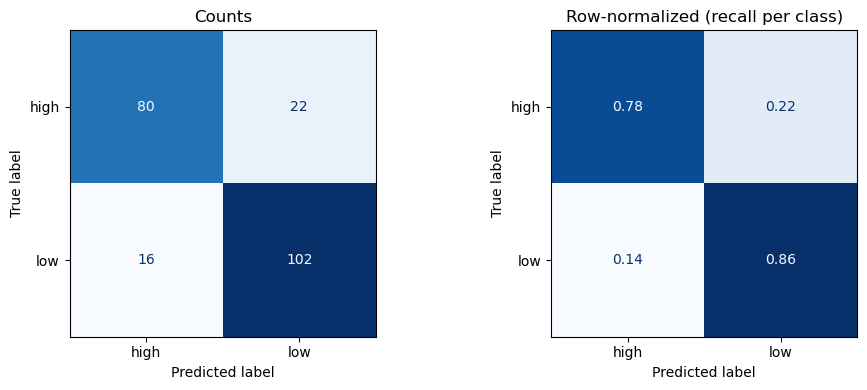

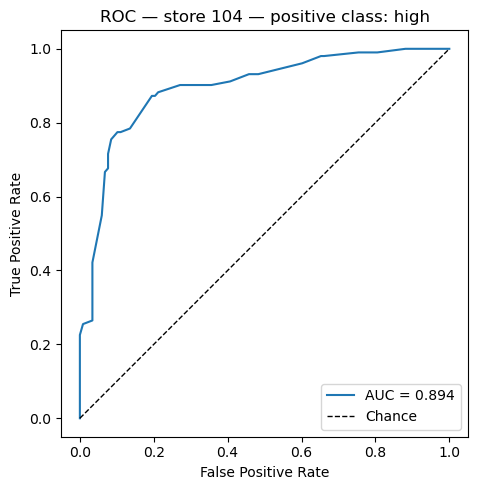

In [58]:
dataset_dict = zero_ratio_profit_Sale_type_dict
FEATURES = ["weekday","zero_stock_level","sale_week_type"]
TARGET = "profit_level"

Naive_Bayes_features = Naive_Bayes_feature_selection_and_split(dataset_dict, FEATURES, TARGET)

# Naive_Bayes_features[104]['train']


Results = Naive_Bayes_Classifier(FEATURES, TARGET, Naive_Bayes_features)

### weekday and zero_stock_level

Store: 104 | Features: ['weekday', 'zero_stock_level']
Train size: 510 | Test size: 220
Accuracy: 0.8227272727272728 | Log loss: 0.42205236642139243
              precision    recall  f1-score   support

        high       0.83      0.77      0.80       102
         low       0.82      0.86      0.84       118

    accuracy                           0.82       220
   macro avg       0.82      0.82      0.82       220
weighted avg       0.82      0.82      0.82       220

AUC: 0.873753738783649


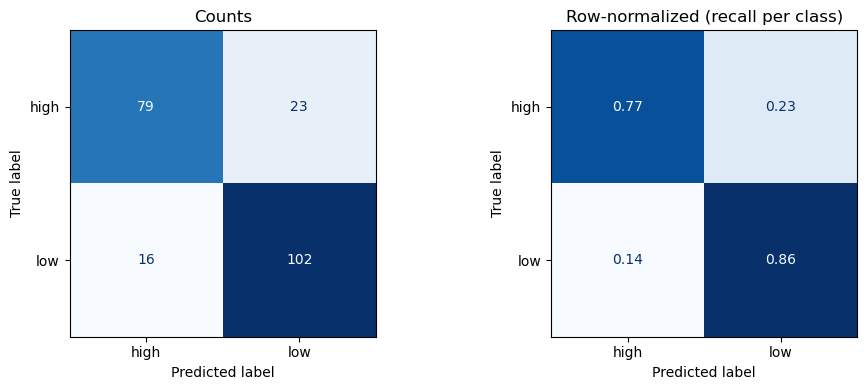

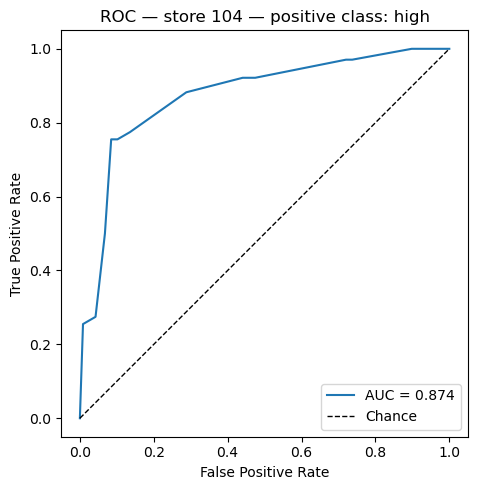

In [42]:
dataset_dict = zero_ratio_profit_Sale_type_dict
FEATURES = ["weekday","zero_stock_level"]
TARGET = "profit_level"

Naive_Bayes_features = Naive_Bayes_feature_selection_and_split(dataset_dict, FEATURES, TARGET)

# Naive_Bayes_features[104]['train']
# store = 104

Results = Naive_Bayes_Classifier(FEATURES, TARGET, Naive_Bayes_features)

### weekday and sale_week_type

Store: 104 | Features: ['weekday', 'sale_week_type']
Train size: 510 | Test size: 220
Accuracy: 0.8090909090909091 | Log loss: 0.45652546924803256
              precision    recall  f1-score   support

        high       0.79      0.79      0.79       102
         low       0.82      0.82      0.82       118

    accuracy                           0.81       220
   macro avg       0.81      0.81      0.81       220
weighted avg       0.81      0.81      0.81       220

AUC: 0.8660684612828181


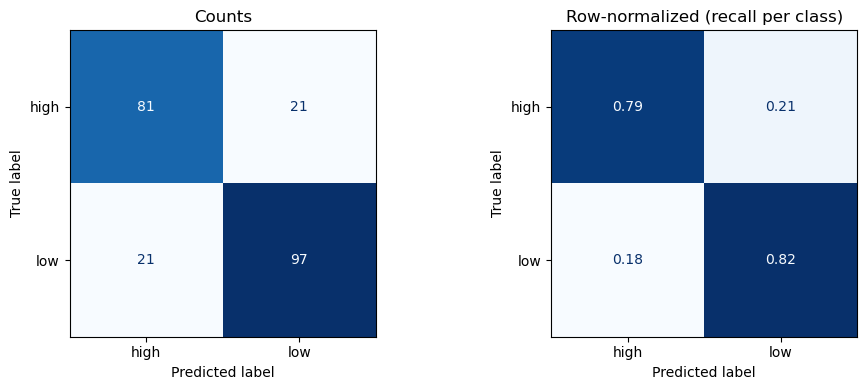

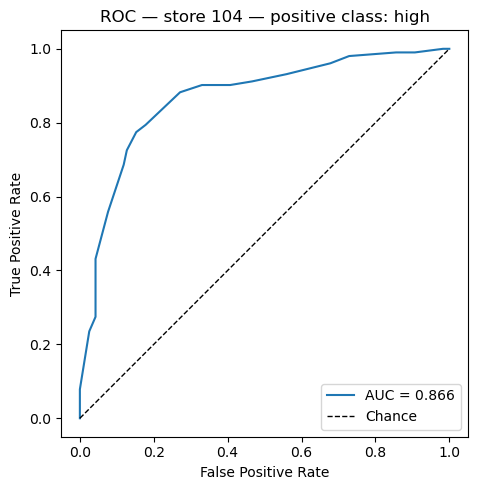

In [43]:
dataset_dict = zero_ratio_profit_Sale_type_dict
FEATURES = ["weekday","sale_week_type"]
TARGET = "profit_level"

Naive_Bayes_features = Naive_Bayes_feature_selection_and_split(dataset_dict, FEATURES, TARGET)

# Naive_Bayes_features[104]['train']
# store = 104

Results = Naive_Bayes_Classifier(FEATURES, TARGET, Naive_Bayes_features)

### sale_week_type and zero_stock_level

Store: 104 | Features: ['sale_week_type', 'zero_stock_level']
Train size: 510 | Test size: 220
Accuracy: 0.6409090909090909 | Log loss: 0.6318432416415264
              precision    recall  f1-score   support

        high       0.58      0.84      0.69       102
         low       0.77      0.47      0.58       118

    accuracy                           0.64       220
   macro avg       0.68      0.65      0.63       220
weighted avg       0.68      0.64      0.63       220

AUC: 0.6679544699235627


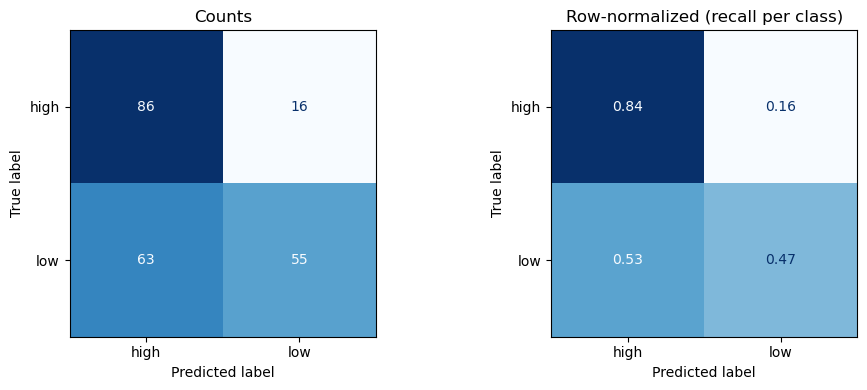

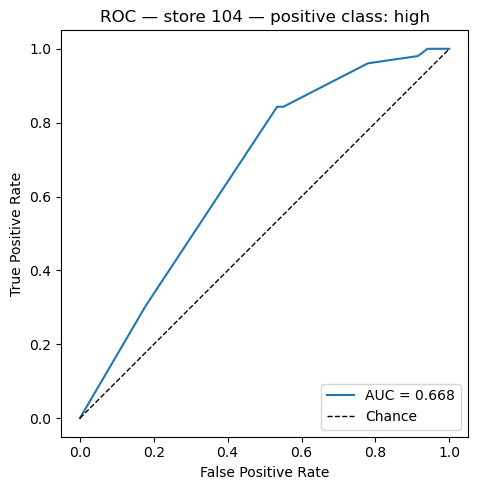

In [44]:
dataset_dict = zero_ratio_profit_Sale_type_dict
FEATURES = ["sale_week_type","zero_stock_level"]
TARGET = "profit_level"

Naive_Bayes_features = Naive_Bayes_feature_selection_and_split(dataset_dict, FEATURES, TARGET)

# Naive_Bayes_features[104]['train']
# store = 104

Results = Naive_Bayes_Classifier(FEATURES, TARGET, Naive_Bayes_features)

In [24]:
import numpy as np
import pandas as pd

Naive_Bayes_features = {}
for store in store_ids:
    df = zero_ratio_profit_Sale_type_dict[store].copy()
    df['date'] = pd.to_datetime(df['date'])

    # Identify the first year in this store's data
    first_year = df['date'].dt.year.min()

    # Mean profit computed on the first year only
    mean_profit = df.loc[df['date'].dt.year == first_year, 'profit'].mean()

    # Apply that threshold to ALL rows (both years)
    df['profit_level'] = np.where(df['profit'] > mean_profit, 'high', 'low')

    # Add weekday
    df['weekday'] = df['date'].dt.day_name()

    # Discretize zero stock
    df['zero_stock_level'] = np.select(
        [df['zero_ratio'].between(0, 0.1, inclusive='left'),
         df['zero_ratio'].between(0.1, 0.3, inclusive='left')],
        ['low', 'moderate'],
        default='high'
    )

    train_df = df[df['date'].dt.year == first_year]
    test_df  = df[df['date'].dt.year ==  first_year + 1]
    Naive_Bayes_features[store] = {
        'train': train_df[["date","weekday","zero_stock_level","sale_week_type","profit_level"]],
        'test':  test_df [["date","weekday","zero_stock_level","sale_week_type","profit_level"]],
    }

In [95]:
Naive_Bayes_features[104]['test']

,date,weekday,zero_stock_level,sale_week_type,profit_level
364,2025-01-01,Wednesday,moderate,Low-promotion,low
365,2025-01-02,Thursday,low,Low-promotion,low
366,2025-01-03,Friday,low,Low-promotion,high
367,2025-01-04,Saturday,low,Low-promotion,high
368,2025-01-05,Sunday,low,Low-promotion,high
...,...,...,...,...,...
724,2025-12-27,Saturday,low,Low-promotion,high
725,2025-12-28,Sunday,low,Low-promotion,high
726,2025-12-29,Monday,low,Low-promotion,low
727,2025-12-30,Tuesday,low,Low-promotion,low


In [96]:
import numpy as np
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import accuracy_score, classification_report, log_loss

FEATURES = ['weekday', 'zero_stock_level', 'sale_week_type']
TARGET   = 'profit_level'

# Pick one store
store = store_ids[0]

train_df = Naive_Bayes_features[store]['train'].copy()
test_df  = Naive_Bayes_features[store]['test'].copy()

# Encode categorical features (declared explicitly so train/test match)
encoder = OrdinalEncoder(categories=[
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'],
    ['low', 'moderate', 'high'],
    ['Low-promotion', 'Other ad week', 'Candidate big-sale'],
])

X_train = encoder.fit_transform(train_df[FEATURES])
X_test  = encoder.transform(test_df[FEATURES])
y_train = train_df[TARGET].values
y_test  = test_df[TARGET].values

# Fit Naive Bayes
model = CategoricalNB(alpha=1.0)
model.fit(X_train, y_train)

# Predict probabilities
proba_test = model.predict_proba(X_test)
classes    = list(model.classes_)
test_df['p_high'] = proba_test[:, classes.index('high')]
test_df['p_low']  = proba_test[:, classes.index('low')]
test_df['pred']   = model.predict(X_test)

# Evaluate
print("Train size:", len(train_df), "| Test size:", len(test_df))
print("Train label counts:\n", train_df[TARGET].value_counts())
print("Test label counts:\n",  test_df[TARGET].value_counts())
print("\nAccuracy:", accuracy_score(y_test, test_df['pred']))
print("\nClassification report:\n", classification_report(y_test, test_df['pred'], zero_division=0))
print("Log loss:", log_loss(y_test, proba_test, labels=classes))

Train size: 364 | Test size: 365
Train label counts:
 profit_level
low     197
high    167
Name: count, dtype: int64
Test label counts:
 profit_level
high    226
low     139
Name: count, dtype: int64

Accuracy: 0.7534246575342466

Classification report:
               precision    recall  f1-score   support

        high       0.87      0.70      0.78       226
         low       0.63      0.83      0.72       139

    accuracy                           0.75       365
   macro avg       0.75      0.77      0.75       365
weighted avg       0.78      0.75      0.76       365

Log loss: 0.5080495743318343


In [97]:
# # Predict on a single new input
# def predict_profit(weekday, zero_stock_level, sale_week_type):
#     X_new = encoder.transform(pd.DataFrame([{
#         'weekday': weekday,
#         'zero_stock_level': zero_stock_level,
#         'sale_week_type': sale_week_type,
#     }])[FEATURES])
#     proba = model.predict_proba(X_new)[0]
#     return dict(zip(model.classes_, proba))

# # Example
# print(predict_profit('Monday', 'moderate', 'Other ad week'))

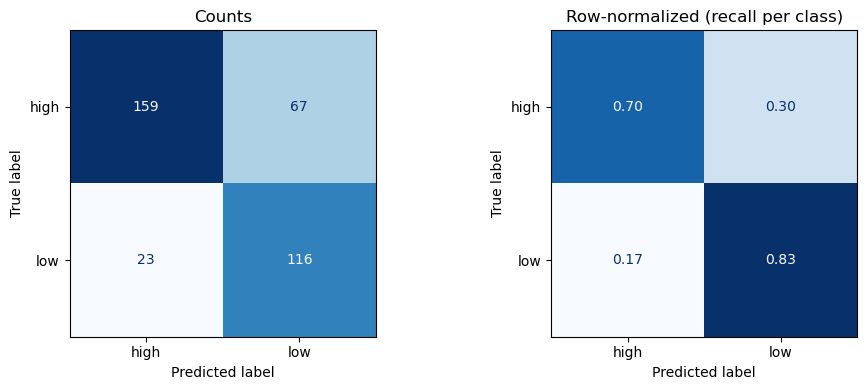

In [98]:
cm = confusion_matrix(y_test, test_df['pred'], labels=labels)
cm_norm = confusion_matrix(y_test, test_df['pred'], labels=labels, normalize='true')

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, mat, fmt, title in zip(
    axes,
    [cm, cm_norm],
    ['d', '.2f'],
    ['Counts', 'Row-normalized (recall per class)']
):
    ConfusionMatrixDisplay(mat, display_labels=labels).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format=fmt
    )
    ax.set_title(title)
plt.tight_layout()
plt.show()

In [102]:
import numpy as np
import pandas as pd

Naive_Bayes_features = {}
for store in store_ids:
    df = zero_ratio_profit_Sale_type_dict[store].copy()
    df['date'] = pd.to_datetime(df['date'])

    # Identify the first year in this store's data
    first_year = df['date'].dt.year.min()

    # Mean profit computed on the first year only
    mean_profit = df.loc[df['date'].dt.year == first_year, 'profit'].mean()

    # Apply that threshold to ALL rows (both years)
    df['profit_level'] = np.where(df['profit'] > mean_profit, 'high', 'low')

    # Add weekday
    df['weekday'] = df['date'].dt.day_name()

    # Discretize zero stock
    df['zero_stock_level'] = np.select(
        [df['zero_ratio'].between(0, 0.1, inclusive='left'),
         df['zero_ratio'].between(0.1, 0.3, inclusive='left')],
        ['low', 'moderate'],
        default='high'
    )

    train_df = df[df['date'].dt.year == first_year]
    test_df  = df[df['date'].dt.year ==  first_year + 1]
    Naive_Bayes_features[store] = {
        'train': train_df[["date","weekday","sale_week_type","profit_level"]],
        'test':  test_df [["date","weekday","sale_week_type","profit_level"]],
    }
Naive_Bayes_features[104]['test']

,date,weekday,sale_week_type,profit_level
364,2025-01-01,Wednesday,Low-promotion,low
365,2025-01-02,Thursday,Low-promotion,low
366,2025-01-03,Friday,Low-promotion,high
367,2025-01-04,Saturday,Low-promotion,high
368,2025-01-05,Sunday,Low-promotion,high
...,...,...,...,...
724,2025-12-27,Saturday,Low-promotion,high
725,2025-12-28,Sunday,Low-promotion,high
726,2025-12-29,Monday,Low-promotion,low
727,2025-12-30,Tuesday,Low-promotion,low


In [103]:
import numpy as np
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import accuracy_score, classification_report, log_loss

FEATURES = ['weekday', 'sale_week_type']
TARGET   = 'profit_level'

# Pick one store
store = store_ids[0]

train_df = Naive_Bayes_features[store]['train'].copy()
test_df  = Naive_Bayes_features[store]['test'].copy()

# Encode categorical features (declared explicitly so train/test match)
encoder = OrdinalEncoder(categories=[
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'],
    ['Low-promotion', 'Other ad week', 'Candidate big-sale'],
])

X_train = encoder.fit_transform(train_df[FEATURES])
X_test  = encoder.transform(test_df[FEATURES])
y_train = train_df[TARGET].values
y_test  = test_df[TARGET].values

# Fit Naive Bayes
model = CategoricalNB(alpha=1.0)
model.fit(X_train, y_train)

# Predict probabilities
proba_test = model.predict_proba(X_test)
classes    = list(model.classes_)
test_df['p_high'] = proba_test[:, classes.index('high')]
test_df['p_low']  = proba_test[:, classes.index('low')]
test_df['pred']   = model.predict(X_test)

# Evaluate
print("Train size:", len(train_df), "| Test size:", len(test_df))
print("Train label counts:\n", train_df[TARGET].value_counts())
print("Test label counts:\n",  test_df[TARGET].value_counts())
print("\nAccuracy:", accuracy_score(y_test, test_df['pred']))
print("\nClassification report:\n", classification_report(y_test, test_df['pred'], zero_division=0))
print("Log loss:", log_loss(y_test, proba_test, labels=classes))

Train size: 364 | Test size: 365
Train label counts:
 profit_level
low     197
high    167
Name: count, dtype: int64
Test label counts:
 profit_level
high    226
low     139
Name: count, dtype: int64

Accuracy: 0.7095890410958904

Classification report:
               precision    recall  f1-score   support

        high       0.88      0.61      0.72       226
         low       0.58      0.87      0.70       139

    accuracy                           0.71       365
   macro avg       0.73      0.74      0.71       365
weighted avg       0.77      0.71      0.71       365

Log loss: 0.567659880207838


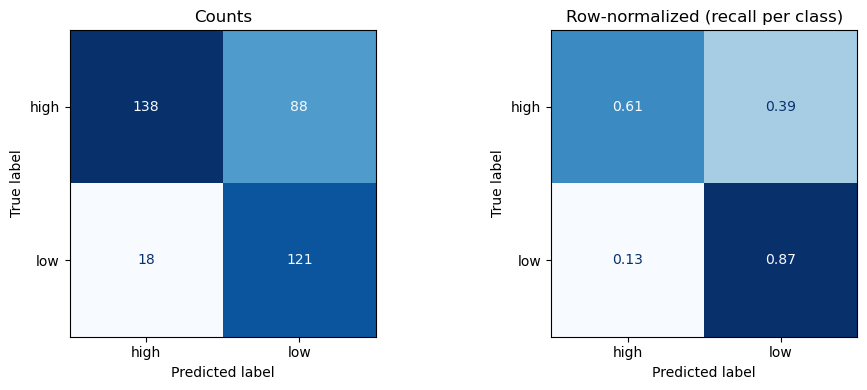

In [104]:
cm = confusion_matrix(y_test, test_df['pred'], labels=labels)
cm_norm = confusion_matrix(y_test, test_df['pred'], labels=labels, normalize='true')

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, mat, fmt, title in zip(
    axes,
    [cm, cm_norm],
    ['d', '.2f'],
    ['Counts', 'Row-normalized (recall per class)']
):
    ConfusionMatrixDisplay(mat, display_labels=labels).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format=fmt
    )
    ax.set_title(title)
plt.tight_layout()
plt.show()

# Single feature classifier

In [45]:
def Naive_Bayes_Classifier_Single_Feature(FEATURE, TARGET, Naive_Bayes_features, store = 104, verbose=True):
    """
    One-feature CategoricalNB for a single store, with ROC/AUC.

    Parameters
    ----------
    FEATURE : str or list of length 1
        One of 'weekday', 'zero_stock_level', 'sale_week_type'.
    TARGET : str
        Target column name (e.g. 'profit_level').
    Naive_Bayes_features : dict
        {store: {'train': df, 'test': df}}.
    store : hashable
        Key into Naive_Bayes_features.
    verbose : bool
        Whether to print metrics and show the figures.

    Returns
    -------
    dict with keys: model, encoder, test_df, accuracy, log_loss, report,
                    auc, fpr, tpr.
    """
    # Accept either a string or a one-element list
    FEATURE = FEATURE[0] if isinstance(FEATURE, (list, tuple)) else FEATURE

    train_df = Naive_Bayes_features[store]['train'].copy()
    test_df  = Naive_Bayes_features[store]['test'].copy()

    if len(train_df) == 0 or len(test_df) == 0:
        raise ValueError(f"Empty split for store {store}: "
                         f"train={len(train_df)}, test={len(test_df)}")

    CATEGORY_MAP = {
        'weekday':          ['Monday', 'Tuesday', 'Wednesday', 'Thursday',
                             'Friday', 'Saturday', 'Sunday'],
        'zero_stock_level': ['low', 'moderate', 'high'],
        'sale_week_type':   ['Low-promotion', 'Other ad week', 'Candidate big-sale'],
    }

    if FEATURE not in CATEGORY_MAP:
        raise ValueError(f"Unknown feature '{FEATURE}'. "
                         f"Expected one of {list(CATEGORY_MAP)}")

    FEATURES = [FEATURE]

    encoder = OrdinalEncoder(
        categories=[CATEGORY_MAP[FEATURE]],
        handle_unknown='use_encoded_value',
        unknown_value=-1,
    )

    X_train = encoder.fit_transform(train_df[FEATURES])
    X_test  = encoder.transform(test_df[FEATURES])
    y_train = train_df[TARGET].values
    y_test  = test_df[TARGET].values

    model = CategoricalNB(alpha=1.0)   # Laplace smoothing
    model.fit(X_train, y_train)

    proba_test = model.predict_proba(X_test)
    classes    = list(model.classes_)
    test_df['p_high'] = proba_test[:, classes.index('high')]
    test_df['p_low']  = proba_test[:, classes.index('low')]
    test_df['pred']   = model.predict(X_test)

    acc    = accuracy_score(y_test, test_df['pred'])
    ll     = log_loss(y_test, proba_test, labels=classes)
    report = classification_report(y_test, test_df['pred'],
                                   output_dict=True, zero_division=0)

    # ---- ROC / AUC ----
    y_true_bin = (y_test == 'high').astype(int)     # positive class = 'high'
    y_score    = test_df['p_high'].values

    if y_true_bin.min() == y_true_bin.max():
        # Only one class present in y_test — ROC is undefined
        auc = np.nan
        fpr = tpr = thresholds = None
        if verbose:
            print(f"\n[WARNING] Test set for store {store} contains only one "
                  f"class in '{TARGET}'; ROC/AUC skipped.")
    else:
        fpr, tpr, thresholds = roc_curve(y_true_bin, y_score)
        auc = roc_auc_score(y_true_bin, y_score)

    if verbose:
        print(f"Store: {store} | Feature: {FEATURE}")
        print("Train size:", len(train_df), "| Test size:", len(test_df))
        print("Train label counts:\n", train_df[TARGET].value_counts())
        print("Test label counts:\n",  test_df[TARGET].value_counts())
        print("Accuracy:", acc, "| Log loss:", ll)
        print(classification_report(y_test, test_df['pred'], zero_division=0))
        print("AUC:", auc)

    # ---- Confusion matrices ----
    labels  = ['high', 'low']
    cm      = confusion_matrix(y_test, test_df['pred'], labels=labels)
    cm_norm = confusion_matrix(y_test, test_df['pred'], labels=labels, normalize='true')

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, mat, fmt, title in zip(
        axes, [cm, cm_norm], ['d', '.2f'],
        ['Counts', 'Row-normalized (recall per class)']
    ):
        ConfusionMatrixDisplay(mat, display_labels=labels).plot(
            ax=ax, cmap='Blues', colorbar=False, values_format=fmt
        )
        ax.set_title(title)
    fig.suptitle(f"Feature: {FEATURE} — store {store}", y=1.02)
    plt.tight_layout()
    plt.show()
    plt.close(fig)

    # ---- ROC curve ----
    if fpr is not None:
        fig, ax = plt.subplots(figsize=(5, 5))
        ax.plot(fpr, tpr, marker='o', label=f'AUC = {auc:.3f}', color='C0')
        ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Chance')
        ax.set_xlabel('False Positive Rate')
        ax.set_ylabel('True Positive Rate')
        ax.set_title(f'ROC — {FEATURE} — store {store} — positive: high')
        ax.legend(loc='lower right')
        ax.set_aspect('equal')
        plt.tight_layout()
        plt.show()
        plt.close(fig)

    return {'model': model, 'encoder': encoder, 'test_df': test_df,
            'accuracy': acc, 'log_loss': ll, 'report': report,
            'auc': auc, 'fpr': fpr, 'tpr': tpr}

In [46]:
# def Naive_Bayes_Classifier_Single_Feature(FEATURE, TARGET, Naive_Bayes_features, store, verbose=True):
#     """
#     One-feature CategoricalNB for a single store.

#     Parameters
#     ----------
#     FEATURE : str
#         One of 'weekday', 'zero_stock_level', 'sale_week_type'.
#     TARGET : str
#         Target column name (e.g. 'profit_level').
#     Naive_Bayes_features : dict
#         {store: {'train': df, 'test': df}}.
#     store : hashable
#         Key into Naive_Bayes_features.
#     verbose : bool
#         Whether to print metrics and show the confusion-matrix figure.

#     Returns
#     -------
#     dict with keys: model, encoder, test_df, accuracy, log_loss, report.
#     """
#     FEATURE = FEATURE[0]
#     train_df = Naive_Bayes_features[store]['train'].copy()
#     test_df  = Naive_Bayes_features[store]['test'].copy()

#     if len(train_df) == 0 or len(test_df) == 0:
#         raise ValueError(f"Empty split for store {store}: "
#                          f"train={len(train_df)}, test={len(test_df)}")

#     CATEGORY_MAP = {
#         'weekday':          ['Monday', 'Tuesday', 'Wednesday', 'Thursday',
#                              'Friday', 'Saturday', 'Sunday'],
#         'zero_stock_level': ['low', 'moderate', 'high'],
#         'sale_week_type':   ['Low-promotion', 'Other ad week', 'Candidate big-sale'],
#     }

#     if FEATURE not in CATEGORY_MAP:
#         raise ValueError(f"Unknown feature '{FEATURE}'. "
#                          f"Expected one of {list(CATEGORY_MAP)}")

#     FEATURES = [FEATURE]   # single-element list for the rest of the pipeline

#     encoder = OrdinalEncoder(
#         categories=[CATEGORY_MAP[FEATURE]],
#         handle_unknown='use_encoded_value',
#         unknown_value=-1,
#     )

#     X_train = encoder.fit_transform(train_df[FEATURES])
#     X_test  = encoder.transform(test_df[FEATURES])
#     y_train = train_df[TARGET].values
#     y_test  = test_df[TARGET].values

#     model = CategoricalNB(alpha=1.0)   # Laplace smoothing
#     model.fit(X_train, y_train)

#     proba_test = model.predict_proba(X_test)
#     classes    = list(model.classes_)
#     test_df['p_high'] = proba_test[:, classes.index('high')]
#     test_df['p_low']  = proba_test[:, classes.index('low')]
#     test_df['pred']   = model.predict(X_test)

#     acc    = accuracy_score(y_test, test_df['pred'])
#     ll     = log_loss(y_test, proba_test, labels=classes)
#     report = classification_report(y_test, test_df['pred'],
#                                    output_dict=True, zero_division=0)

#     if verbose:
#         print(f"Store: {store} | Feature: {FEATURE}")
#         print("Train size:", len(train_df), "| Test size:", len(test_df))
#         print("Train label counts:\n", train_df[TARGET].value_counts())
#         print("Test label counts:\n",  test_df[TARGET].value_counts())
#         print("Accuracy:", acc, "| Log loss:", ll)
#         print(classification_report(y_test, test_df['pred'], zero_division=0))

#     labels  = ['high', 'low']
#     cm      = confusion_matrix(y_test, test_df['pred'], labels=labels)
#     cm_norm = confusion_matrix(y_test, test_df['pred'], labels=labels, normalize='true')

#     fig, axes = plt.subplots(1, 2, figsize=(10, 4))
#     for ax, mat, fmt, title in zip(
#         axes, [cm, cm_norm], ['d', '.2f'],
#         ['Counts', 'Row-normalized (recall per class)']
#     ):
#         ConfusionMatrixDisplay(mat, display_labels=labels).plot(
#             ax=ax, cmap='Blues', colorbar=False, values_format=fmt
#         )
#         ax.set_title(title)
#     fig.suptitle(f"Feature: {FEATURE} — store {store}", y=1.02)
#     plt.tight_layout()
#     plt.show()
#     plt.close(fig)

#     return {'model': model, 'encoder': encoder, 'test_df': test_df,
#             'accuracy': acc, 'log_loss': ll, 'report': report}

#### Weekday

In [47]:
store

318

Store: 104 | Feature: weekday
Train size: 510 | Test size: 220
Train label counts:
 profit_level
low     272
high    238
Name: count, dtype: int64
Test label counts:
 profit_level
low     118
high    102
Name: count, dtype: int64
Accuracy: 0.8136363636363636 | Log loss: 0.48221813646217593
              precision    recall  f1-score   support

        high       0.81      0.77      0.79       102
         low       0.81      0.85      0.83       118

    accuracy                           0.81       220
   macro avg       0.81      0.81      0.81       220
weighted avg       0.81      0.81      0.81       220

AUC: 0.8429295446992356


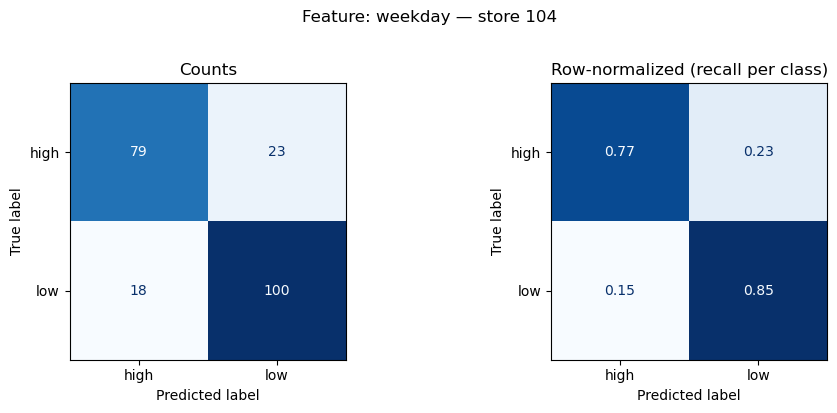

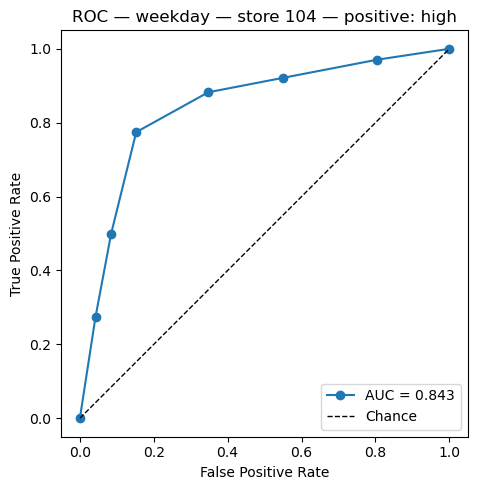

In [48]:
dataset_dict = zero_ratio_profit_Sale_type_dict
FEATURES = ["weekday"]
TARGET = "profit_level"

Naive_Bayes_features = Naive_Bayes_feature_selection_and_split(dataset_dict, FEATURES, TARGET)

# Naive_Bayes_features[104]['train']
# store = 104

Results1 = Naive_Bayes_Classifier_Single_Feature(FEATURES, TARGET, Naive_Bayes_features, verbose=True)

### Zero stock level

Store: 104 | Feature: zero_stock_level
Train size: 510 | Test size: 220
Train label counts:
 profit_level
low     272
high    238
Name: count, dtype: int64
Test label counts:
 profit_level
low     118
high    102
Name: count, dtype: int64
Accuracy: 0.5727272727272728 | Log loss: 0.6451665855115393
              precision    recall  f1-score   support

        high       0.52      0.96      0.68       102
         low       0.88      0.24      0.37       118

    accuracy                           0.57       220
   macro avg       0.70      0.60      0.52       220
weighted avg       0.71      0.57      0.51       220

AUC: 0.6001994017946162


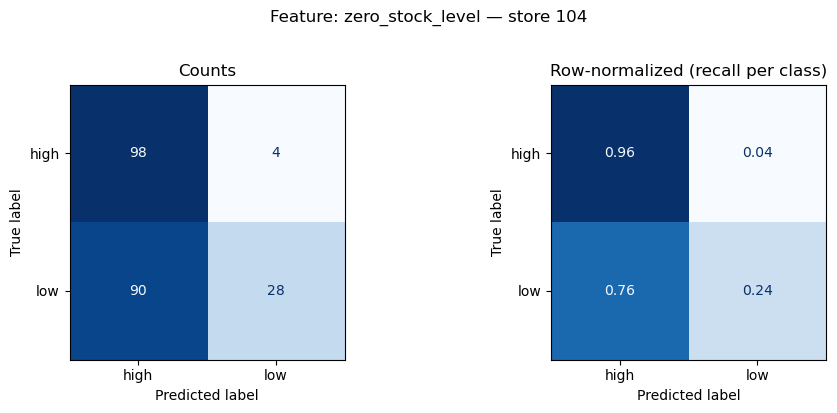

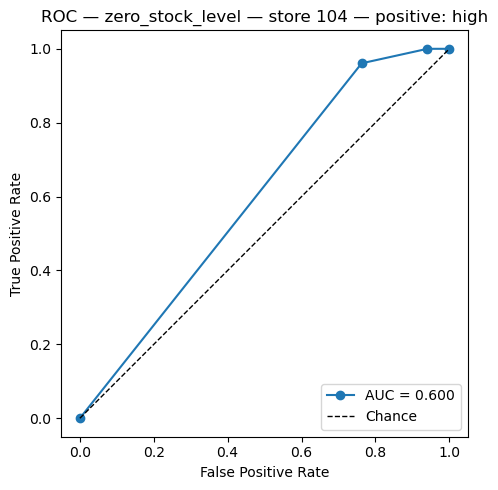

In [49]:
dataset_dict = zero_ratio_profit_Sale_type_dict
FEATURES = ["zero_stock_level"]
TARGET = "profit_level"

Naive_Bayes_features = Naive_Bayes_feature_selection_and_split(dataset_dict, FEATURES, TARGET)

# Naive_Bayes_features[104]['train']
# store = 104

Results = Naive_Bayes_Classifier_Single_Feature(FEATURES, TARGET, Naive_Bayes_features, verbose=True)

### Sale week type

Store: 104 | Feature: sale_week_type
Train size: 510 | Test size: 220
Train label counts:
 profit_level
low     272
high    238
Name: count, dtype: int64
Test label counts:
 profit_level
low     118
high    102
Name: count, dtype: int64
Accuracy: 0.5727272727272728 | Log loss: 0.673680256580702
              precision    recall  f1-score   support

        high       0.57      0.30      0.40       102
         low       0.57      0.81      0.67       118

    accuracy                           0.57       220
   macro avg       0.57      0.55      0.53       220
weighted avg       0.57      0.57      0.54       220

AUC: 0.5936357593885011


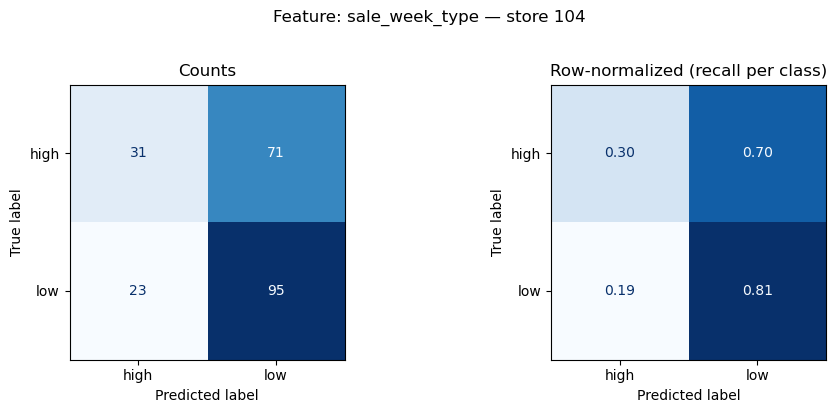

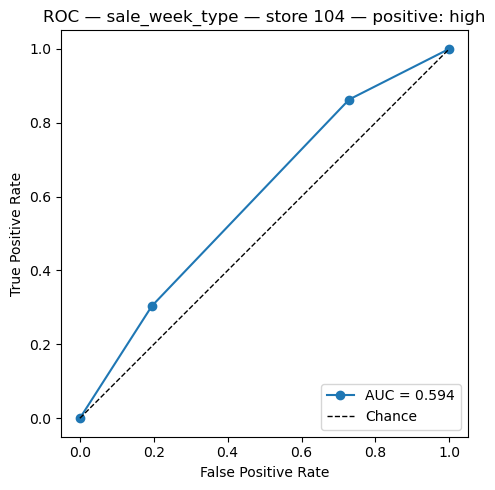

In [50]:
dataset_dict = zero_ratio_profit_Sale_type_dict
FEATURES = ["sale_week_type"]
TARGET = "profit_level"

Naive_Bayes_features = Naive_Bayes_feature_selection_and_split(dataset_dict, FEATURES, TARGET)

# Naive_Bayes_features[104]['train']
# store = 104

Results = Naive_Bayes_Classifier_Single_Feature(FEATURES, TARGET, Naive_Bayes_features, verbose=True)